<a href="https://colab.research.google.com/github/Yeaser28/Ml-Dl/blob/main/FirstMLProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [461]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [462]:
df = pd.read_csv('/content/student_placement_float_iq.csv') # Calling the dataset in the code.

In [463]:
df.head()

,Serial_No,CGPA,IQ,Placement
0,1,2.59,107.36,0
1,2,2.94,115.82,0
2,3,3.96,108.43,1
3,4,2.36,120.12,0
4,5,3.06,125.65,1


In [464]:
df.shape


(100, 4)

In [465]:
df = df.iloc[:, 1:] # Separating useless features.
df.head()

,CGPA,IQ,Placement
0,2.59,107.36,0
1,2.94,115.82,0
2,3.96,108.43,1
3,2.36,120.12,0
4,3.06,125.65,1


In [466]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   CGPA       100 non-null    float64
 1   IQ         100 non-null    float64
 2   Placement  100 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


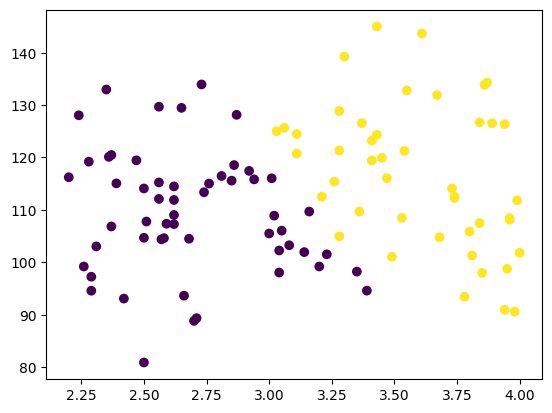

In [467]:
plt.scatter(df['CGPA'],df['IQ'],c=df['Placement'])

In [468]:
x = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [469]:
x

,CGPA,IQ
0,2.59,107.36
1,2.94,115.82
2,3.96,108.43
3,2.36,120.12
4,3.06,125.65
...,...,...
95,3.95,98.77
96,3.87,134.28
97,3.30,139.24
98,3.80,105.87


In [470]:
y

,Placement
0,0
1,0
2,1
3,0
4,1
...,...
95,1
96,1
97,1
98,1


In [471]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.1) # Spliting train and test datas.

In [472]:
y_train

,Placement
45,0
93,0
47,1
86,0
22,0
...,...
76,0
30,1
28,0
38,0


In [473]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train) # Scaling datas.
x_test = scaler.transform(x_test)

x = scaler.fit_transform(x)

In [474]:
x_train

array([[-1.08116451,  0.25834894],
       [-1.55032944, -0.70624623],
       [ 0.75796201,  0.73314149],
       [-0.96856493, -0.36970443],
       [-0.96856493,  0.19830862],
       [ 1.33972652, -1.10440837],
       [ 0.30756368,  2.15435911],
       [ 1.50862589, -1.66215136],
       [ 1.35849311,  1.72933683],
       [ 1.54615909, -0.27964394],
       [ 0.04483132, -0.18089341],
       [ 1.37725971,  1.76251701],
       [ 1.11452735,  0.16670845],
       [ 0.27003048,  0.74025153],
       [-0.96856493, -0.23224369],
       [ 1.52739249, -1.04278804],
       [ 1.41479291,  1.15026373],
       [ 0.27003048, -0.55377541],
       [-0.79966556, -1.78776203],
       [ 1.32095992, -0.35469435],
       [-0.5181666 ,  0.51984034],
       [-1.45649645,  0.64387101],
       [-0.18036785, -0.76707656],
       [ 0.1761975 , -0.82553687],
       [ 1.02069437, -0.5687855 ],
       [ 0.23249729,  0.269409  ],
       [-1.64416243, -1.00881786],
       [ 1.54615909, -0.30571408],
       [-0.04900167,

In [475]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression()

clf.fit(x_train,y_train) # training model

y_pred = clf.predict(x_test) # testing model

from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred) # checking accuracy

1.0

<Axes: >

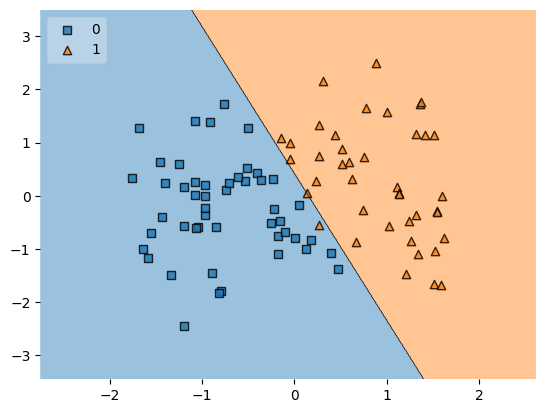

In [476]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(x_train,y_train.values,clf=clf,legend=2) # checking the algo.

In [477]:

from sklearn.model_selection import cross_val_score

clf = LogisticRegression()

# model training:
scores = cross_val_score(clf, x, y, cv=5, scoring='accuracy') # training model in 5 stages.

print("প্রতিটি ফোল্ডের অ্যাকুরেসি:", scores)
print("গড় (Average) অ্যাকুরেসি:", scores.mean() * 100, "%")

প্রতিটি ফোল্ডের অ্যাকুরেসি: [1.   1.   0.95 1.   1.  ]
গড় (Average) অ্যাকুরেসি: 99.0 %


In [479]:
import pickle
pickle.dump(clf,open('model.pkl','wb')) # saving the model

In [478]:
# Steps

# 0. Preprocess + EDA + Feature Selection
# 1. Extract input and output cols
# 2. Scale the values
# 3. Train test split
# 4. Train the model
# 5. Evaluate the model/model selection
# 6. Deploy the model